# Candlestick with Moving Averages, Bollinger Band & Volume

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

The technical analyst's standard price panel. Candles show each day's open, high, low and close. 20- and 50-day moving averages show trend, a Bollinger band shows how unusual the price is relative to its own recent volatility, and a separate volume panel shows conviction.

## When to use

- Review a single security's recent price action with trend and volatility context
- Spot moving-average crossovers, band squeezes or breakouts, and volume spikes
- Present to trading or portfolio-management audiences who read this format daily

## Avoid when

- The audience only needs the trend (a line of closing prices is clearer)
- More than ~150 periods are shown (candles turn into noise; aggregate to weekly)
- Putting volume on a second y-axis over the price (always give it its own panel)

## Alternatives

- Basic candlestick (05 · Change over time)
- Line of closing price with MA overlay
- Cumulative return vs benchmark

## Design tips

- Keep indicator lines thinner and calmer than the candles; the price is the hero
- Moving averages need a warm-up window, so compute them on more history than you show
- Color volume bars by up/down day so volume and price read together
- Label the indicators directly at the right edge instead of relying only on a legend

## Example

120 trading days of a simulated stock (illustrative), with 20/50-day moving averages, a 20-day ±2σ Bollinger band and daily volume with its 20-day average.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(21)
n_total, n_show = 170, 120          # extra history warms up the 50-day average
dates = pd.bdate_range("2025-01-02", periods=n_total)
ret = rng.normal(0.0006, 0.016, n_total)
ret[95:115] += 0.004                # a rally
ret[140:152] -= 0.007               # a pullback
close = 80 * np.exp(np.cumsum(ret))
open_ = np.r_[80, close[:-1]] * (1 + rng.normal(0, 0.004, n_total))
high = np.maximum(open_, close) * (1 + rng.uniform(0.001, 0.014, n_total))
low = np.minimum(open_, close) * (1 - rng.uniform(0.001, 0.014, n_total))
volume = rng.lognormal(np.log(2e6), 0.3, n_total) * (1 + 10 * np.abs(ret))

df = pd.DataFrame({"open": open_, "high": high, "low": low, "close": close,
                   "volume": volume}, index=dates)
df["ma20"] = df["close"].rolling(20).mean()
df["ma50"] = df["close"].rolling(50).mean()
sd20 = df["close"].rolling(20).std()
df["bb_upper"] = df["ma20"] + 2 * sd20
df["bb_lower"] = df["ma20"] - 2 * sd20
df["vol_ma20"] = df["volume"].rolling(20).mean()
df = df.iloc[-n_show:].round(2)
df.tail()

,open,high,low,close,volume,ma20,ma50,bb_upper,bb_lower,vol_ma20
2025-08-21,77.74,78.68,76.77,78.24,4027367.94,77.74,85.30,80.77,74.70,2635206.54
2025-08-22,78.48,79.13,76.35,77.40,2278518.77,77.47,84.90,79.44,75.51,2626507.77
2025-08-25,77.31,78.03,77.02,77.94,1993248.83,77.36,84.54,78.84,75.87,2633807.72
2025-08-26,78.12,78.78,77.24,77.53,2824703.84,77.31,84.21,78.71,75.91,2608847.28
2025-08-27,77.64,77.93,76.64,77.49,2007686.36,77.32,83.87,78.72,75.92,2611365.46


### Plot

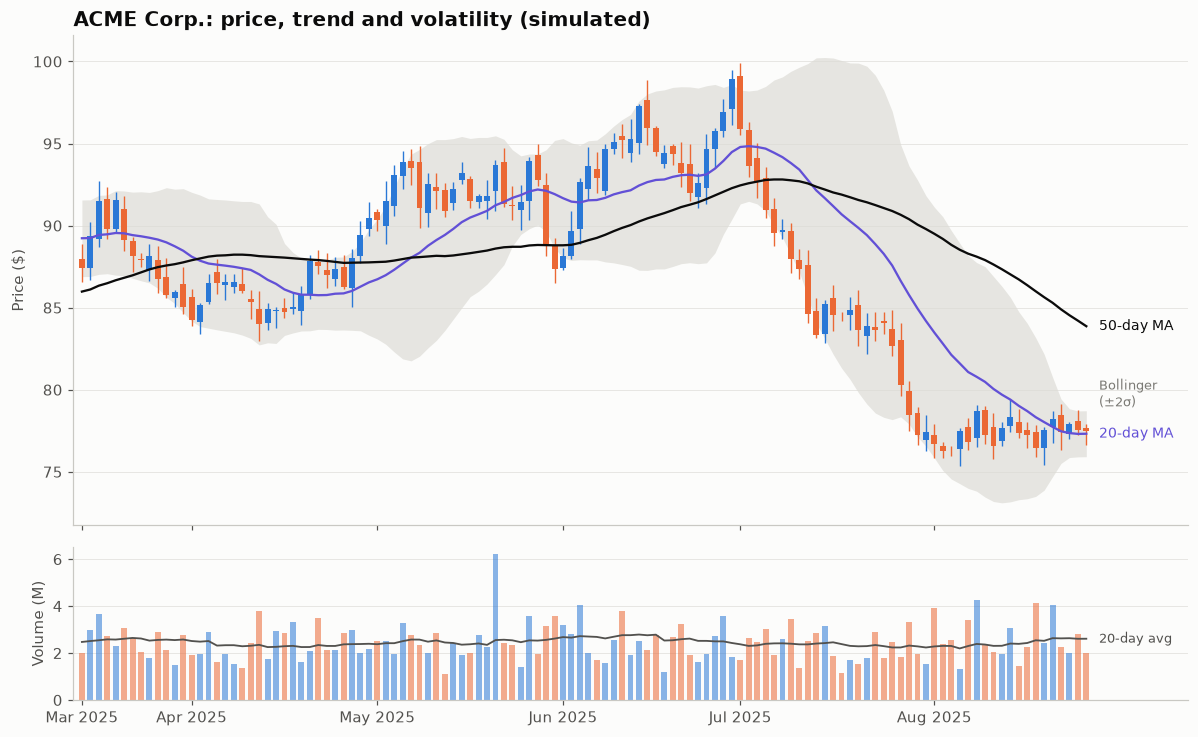

In [3]:
fig, (ax, axv) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True,
                              gridspec_kw={"height_ratios": [3.2, 1]})
x = np.arange(len(df))
up = (df["close"] >= df["open"]).to_numpy()
colors = np.where(up, PALETTE[0], PALETTE[1])

ax.fill_between(x, df["bb_lower"], df["bb_upper"], color="#dddcd6", alpha=0.7, linewidth=0)
ax.vlines(x, df["low"], df["high"], color=colors, linewidth=0.9)
ax.bar(x, (df["close"] - df["open"]).abs().clip(lower=0.03),
       bottom=df[["open", "close"]].min(axis=1), color=colors, width=0.7)
ax.plot(x, df["ma20"], color=PALETTE[6], linewidth=1.5)
ax.plot(x, df["ma50"], color="#0b0b0b", linewidth=1.5)
end = len(df) - 1
for col, label, color in [("ma20", "20-day MA", PALETTE[6]), ("ma50", "50-day MA", "#0b0b0b")]:
    ax.text(end + 1.5, df[col].iloc[-1], label, color=color, va="center", fontsize=9)
ax.text(end + 1.5, df["bb_upper"].iloc[-1], "Bollinger\n(±2σ)", color="#7a7974",
        va="bottom", fontsize=8.5)
ax.set_xlim(-1, len(df) + 11)
ax.set_ylabel("Price ($)")
ax.set_title("ACME Corp.: price, trend and volatility (simulated)")

axv.bar(x, df["volume"] / 1e6, color=colors, width=0.7, alpha=0.55)
axv.plot(x, df["vol_ma20"] / 1e6, color="#52514e", linewidth=1.2)
axv.text(end + 1.5, df["vol_ma20"].iloc[-1] / 1e6, "20-day avg", color="#52514e",
         va="center", fontsize=8.5)
axv.set_ylabel("Volume (M)")

month_start = np.flatnonzero(df.index.month != np.r_[0, df.index.month[:-1]])
axv.set_xticks(month_start, df.index[month_start].strftime("%b %Y"))
for a in (ax, axv):
    a.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

When the price stays above a rising 50-day MA the trend is up. When it leaves the gray band the move is unusually large for this stock. Tall volume bars mark the days the market cared most.

---
Standalone script: [`candlestick_ma_volume.py`](candlestick_ma_volume.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)